In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.layers import (
    Embedding,
    Dense,
    LayerNormalization,
    Dropout,
    Input
)

from tensorflow.keras.models import Model

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))



TensorFlow Version: 2.21.0
GPU Available: []


In [ ]:
text_data = """
I love machine learning.
Machine learning is interesting.
Deep learning is a part of machine learning.
Transformers are powerful deep learning models.
Artificial intelligence is changing the world.
I love artificial intelligence.
Python is a popular programming language.
Deep learning uses neural networks.
Machine learning helps computers learn from data.
Transformers use self attention mechanisms.
"""

print(text_data)


I love machine learning.
Machine learning is interesting.
Deep learning is a part of machine learning.
Transformers are powerful deep learning models.
Artificial intelligence is changing the world.
I love artificial intelligence.
Python is a popular programming language.
Deep learning uses neural networks.
Machine learning helps computers learn from data.
Transformers use self attention mechanisms.



In [ ]:
import re

# Convert text into lowercase words
tokens = re.findall(r"\b\w+\b", text_data.lower())

# Repeat the dataset 100 times
tokens = tokens * 100

# Create vocabulary
vocabulary = sorted(set(tokens))

# Assign a unique number to each word
word_to_id = {
    word: index + 1
    for index, word in enumerate(vocabulary)
}

# Create reverse mapping
id_to_word = {
    index: word
    for word, index in word_to_id.items()
}

# Convert words into numbers
encoded_text = [word_to_id[word] for word in tokens]

vocab_size = len(vocabulary) + 1

print("Vocabulary:", vocabulary)
print("Vocabulary Size:", vocab_size)
print("Encoded Text:", encoded_text[:20])

Vocabulary: ['a', 'are', 'artificial', 'attention', 'changing', 'computers', 'data', 'deep', 'from', 'helps', 'i', 'intelligence', 'interesting', 'is', 'language', 'learn', 'learning', 'love', 'machine', 'mechanisms', 'models', 'networks', 'neural', 'of', 'part', 'popular', 'powerful', 'programming', 'python', 'self', 'the', 'transformers', 'use', 'uses', 'world']
Vocabulary Size: 36
Encoded Text: [11, 18, 19, 17, 19, 17, 14, 13, 8, 17, 14, 1, 25, 24, 19, 17, 32, 2, 27, 8]


In [ ]:
# Create training sequences (X) and next-word targets (y)
sequence_length = 3
X_list = []
y_list = []

for i in range(len(encoded_text) - sequence_length):
    X_list.append(encoded_text[i : i + sequence_length])
    y_list.append(encoded_text[i + sequence_length])

X = np.array(X_list)
y = np.array(y_list)

# Shuffle the examples
np.random.seed(42)
indices = np.random.permutation(len(X))

X = X[indices]
y = y[indices]

# 80% training and 20% testing
split = int(0.8 * len(X))

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

X shape: (5497, 3)
y shape: (5497,)
Training samples: 4397
Testing samples: 1100


In [ ]:
context_length = sequence_length
embedding_dim = 64

# Token embedding
token_embedding = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim
)

# Positional embedding
position_embedding = Embedding(
    input_dim=context_length,
    output_dim=embedding_dim
)

# Test embeddings
sample_input = tf.constant(X_train[:2])

positions = tf.range(
    start=0,
    limit=context_length,
    delta=1
)

token_vectors = token_embedding(sample_input)

position_vectors = position_embedding(positions)

combined_embeddings = token_vectors + position_vectors

print("Token embedding shape:", token_vectors.shape)
print("Position embedding shape:", position_vectors.shape)
print("Combined embedding shape:", combined_embeddings.shape)

Token embedding shape: (2, 3, 64)
Position embedding shape: (3, 64)
Combined embedding shape: (2, 3, 64)


In [ ]:
class SelfAttention(tf.keras.layers.Layer):

    def __init__(self, embedding_dim):
        super().__init__()

        self.query = Dense(embedding_dim)
        self.key = Dense(embedding_dim)
        self.value = Dense(embedding_dim)

        self.embedding_dim = embedding_dim

    def call(self, inputs):

        Q = self.query(inputs)
        K = self.key(inputs)
        V = self.value(inputs)

        # Calculate attention scores
        scores = tf.matmul(Q, K, transpose_b=True)

        scores = scores / tf.math.sqrt(
            tf.cast(self.embedding_dim, tf.float32)
        )

        # Create causal mask
        seq_length = tf.shape(inputs)[1]

        mask = tf.linalg.band_part(
            tf.ones((seq_length, seq_length)),
            -1,
            0
        )

        # Prevent looking at future tokens
        mask = tf.cast(mask, tf.bool)

        scores = tf.where(
            mask,
            scores,
            tf.ones_like(scores) * -1e9
        )

        # Calculate attention weights
        attention_weights = tf.nn.softmax(scores, axis=-1)

        # Combine values
        output = tf.matmul(attention_weights, V)

        return output

In [ ]:
attention_layer = SelfAttention(embedding_dim)

attention_output = attention_layer(combined_embeddings)

print("Attention output shape:", attention_output.shape)

Attention output shape: (2, 3, 64)


In [ ]:
def build_transformer():

    # Input layer
    inputs = Input(shape=(context_length,))

    # Token embedding
    token_emb = Embedding(
        vocab_size,
        embedding_dim
    )(inputs)

    # Positional embedding
    positions = tf.range(
        start=0,
        limit=context_length,
        delta=1
    )

    pos_emb = position_embedding(positions)

    # Combine token and position embeddings
    x = token_emb + pos_emb

    # Self-attention
    attention = SelfAttention(embedding_dim)(x)

    # Residual connection and normalization
    x = LayerNormalization()(x + attention)

    # Feed-forward network
    ff = Dense(128, activation="relu")(x)

    ff = Dense(embedding_dim)(ff)

    # Residual connection and normalization
    x = LayerNormalization()(x + ff)

    # Extract final token representation
    x = x[:, -1, :]

    # Predict next token
    outputs = Dense(vocab_size)(x)

    model = Model(inputs, outputs)

    return model


model = build_transformer()

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_6         │ (None, 3, 64)     │      2,304 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 3, 64)     │          0 │ embedding_6[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_3    │ (None, 3, 64)     │     12,480 │ add_3[0][0]       │
│ (SelfAttention)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 3, 64)     │          0 │ add_3[0][0],      │
│                     │                   │            │ self_attention_3… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 3, 64)     │        128 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 3, 128)    │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 3, 64)     │      8,256 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 3, 64)     │          0 │ layer_normalizat… │
│                     │                   │            │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 3, 64)     │        128 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 64)        │          0 │ layer_normalizat… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 36)        │      2,340 │ get_item_1[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 33,956 (132.64 KB)

 Trainable params: 33,956 (132.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),

    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    X_train,
    y_train,

    validation_data=(X_test, y_test),

    epochs=50,

    batch_size=16,

    verbose=1
)

Epoch 1/50
275/275 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9354 - loss: 0.3134 - val_accuracy: 1.0000 - val_loss: 0.0108
Epoch 2/50
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 0.0063 - val_accuracy: 1.0000 - val_loss: 0.0038
Epoch 3/50
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 1.0000 - val_loss: 0.0021
Epoch 4/50
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 5/50
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 9.0201e-04
Epoch 6/50
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 7.6856e-04 - val_accuracy: 1.0000 - val_loss: 6.5923e-04
Epoch 7/50
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 1.0000 - loss: 5.7214e-04 - val_accuracy: 1.0000 - val_loss: 4.9987e-04
Epoch 8/50
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 1.0000 - loss: 4.394

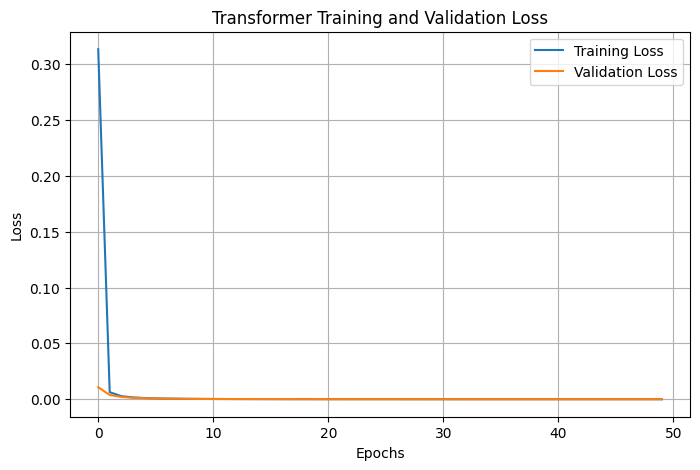

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Transformer Training and Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

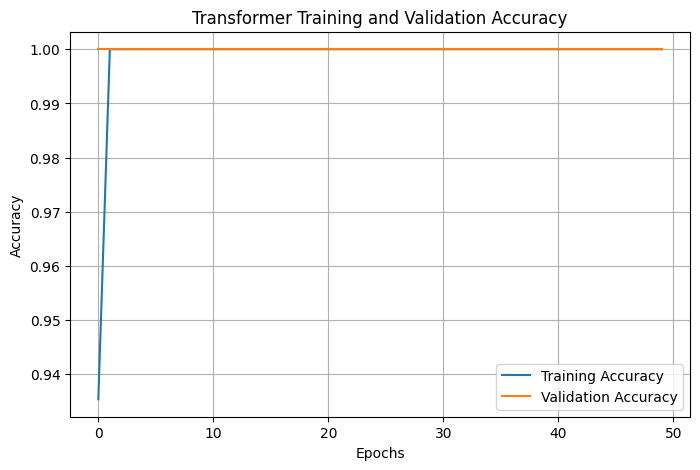

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Transformer Training and Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

Test Loss: 4.565715130411263e-07
Test Accuracy: 100.0 %


In [ ]:
def predict_next_word(input_text):

    # Convert input into lowercase tokens
    input_tokens = re.findall(
        r"\b\w+\b",
        input_text.lower()
    )

    # Check vocabulary
    unknown_words = [
        word for word in input_tokens
        if word not in word_to_id
    ]

    if unknown_words:
        print("Unknown words:", unknown_words)
        return

    # Convert words into numbers
    input_ids = [
        word_to_id[word]
        for word in input_tokens
    ]

    # Keep the last five tokens
    input_ids = input_ids[-context_length:]

    if len(input_ids) < context_length:
        print("Please enter at least five known words.")
        return

    # Convert to array
    input_array = np.array([input_ids])

    # Predict next token scores
    predictions = model.predict(
        input_array,
        verbose=0
    )

    # Convert scores into probabilities
    probabilities = tf.nn.softmax(
        predictions[0]
    ).numpy()

    # Get the most likely token
    predicted_id = np.argmax(probabilities)

    predicted_word = id_to_word.get(
        predicted_id,
        "Unknown"
    )

    print("Input Text:", input_text)

    print("Predicted Next Word:", predicted_word)

    print(
        "Prediction Confidence:",
        round(float(probabilities[predicted_id]) * 100, 2),
        "%"
    )

In [ ]:
predict_next_word("machine learning is a part")

Input Text: machine learning is a part
Predicted Next Word: of
Prediction Confidence: 100.0 %


In [ ]:
predict_next_word("I love machine learning")

Input Text: I love machine learning
Predicted Next Word: machine
Prediction Confidence: 100.0 %


In [ ]:
def predict_top_5(input_text):

    input_tokens = re.findall(
        r"\b\w+\b",
        input_text.lower()
    )

    if any(word not in word_to_id for word in input_tokens):
        print("Input contains unknown words.")
        return

    input_ids = [
        word_to_id[word]
        for word in input_tokens
    ][-context_length:]

    if len(input_ids) < context_length:
        print("Enter at least five words.")
        return

    input_array = np.array([input_ids])

    predictions = model.predict(
        input_array,
        verbose=0
    )

    probabilities = tf.nn.softmax(
        predictions[0]
    ).numpy()

    top_indices = np.argsort(probabilities)[-5:][::-1]

    print("Input:", input_text)
    print("\nTop 5 Predictions:")

    for index in top_indices:

        word = id_to_word.get(index, "Unknown")

        probability = probabilities[index] * 100

        print(f"{word}: {probability:.2f}%")

In [ ]:
predict_top_5("machine learning is a part")

Input: machine learning is a part

Top 5 Predictions:
of: 100.00%
data: 0.00%
are: 0.00%
uses: 0.00%
i: 0.00%


In [ ]:
model.save_weights("transformer_model.weights.h5")

print("Model weights saved successfully!")

Model weights saved successfully!


In [ ]:
import json

with open("vocabulary.json", "w") as file:

    json.dump(word_to_id, file)

print("Vocabulary saved successfully!")

Vocabulary saved successfully!


In [1]:
import shutil

shutil.make_archive('/content/MyProject', 'zip', '/content/MyProject')

FileNotFoundError: [Errno 2] No such file or directory: '/content/MyProject'

In [2]:
!ls /content

sample_data
